In [34]:
# Experiment No. 9
# Advanced Visualization Techniques for Multi-Dimensional Data
# Dataset: Student Performance Factors (Kaggle)

In [35]:
# ------------------------------------------
# Step 1: Import Required Libraries
# ------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")


In [36]:

# ------------------------------------------
# Step 2: Load Kaggle Dataset
# ------------------------------------------

df = pd.read_csv("StudentPerformanceFactors.csv")

print("First Five Records:")
print(df.head())


First Five Records:
   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65           Medium   

  Internet_Access  Tutoring_Sessions Family_Income Teacher_Quality

In [37]:

# ------------------------------------------
# Step 3: Dataset Information
# ------------------------------------------

print("\nDataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nStatistical Summary:")
print(df.describe())




Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 1

In [38]:

# ------------------------------------------
# Step 4: Data Cleaning
# ------------------------------------------

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Select numerical columns
numeric_df = df.select_dtypes(include=np.number).copy()

# Handle missing values using median
numeric_df = numeric_df.fillna(numeric_df.median())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# ------------------------------------------
# Step 4: Data Cleaning
# ------------------------------------------

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Select numerical columns
numeric_df = df.select_dtypes(include=np.number).copy()

# Handle missing values using median
numeric_df = numeric_df.fillna(numeric_df.median())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())



Missing Values:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

Duplicate Records: 0

Missing Values:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Interne

In [39]:

# ------------------------------------------
# Step 5: Select Important Features
# ------------------------------------------

features = [
    'Hours_Studied',
    'Attendance',
    'Sleep_Hours',
    'Previous_Scores',
    'Tutoring_Sessions',
    'Physical_Activity',
    'Exam_Score'
]

# Select required numerical features
plot_df = numeric_df[features]

print("\nSelected Numerical Features:")
print(plot_df.head())



Selected Numerical Features:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0             23          84            7               73                  0   
1             19          64            8               59                  2   
2             24          98            7               91                  2   
3             29          89            8               98                  1   
4             19          92            6               65                  3   

   Physical_Activity  Exam_Score  
0                  3          67  
1                  4          61  
2                  4          74  
3                  4          71  
4                  4          70  


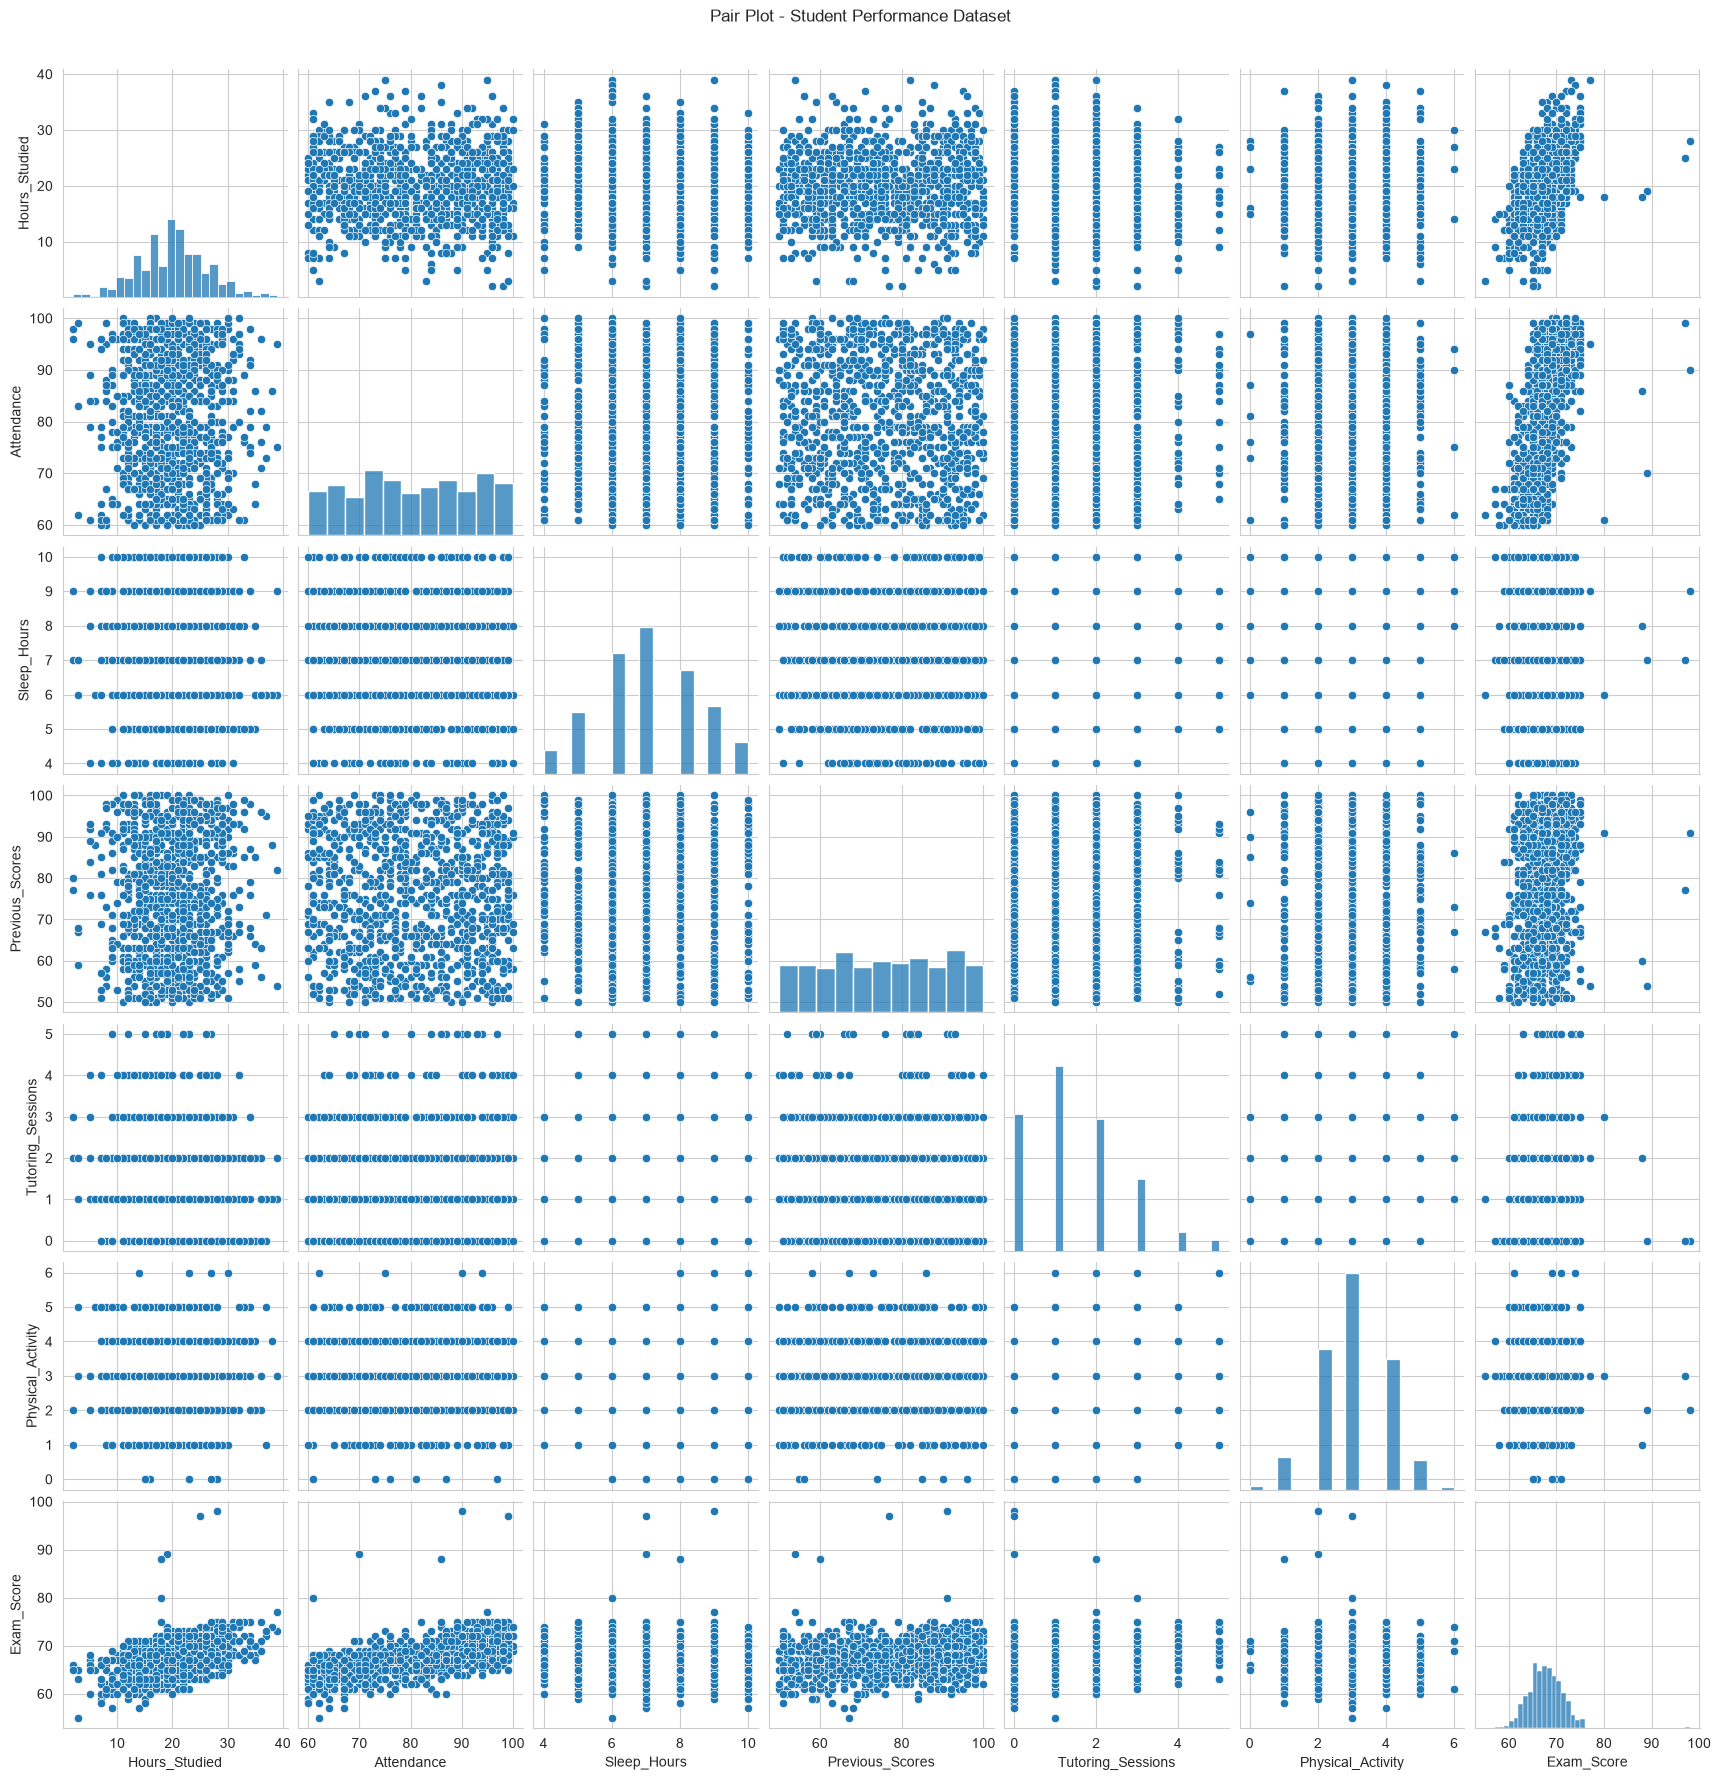

In [40]:

# ------------------------------------------
# Step 6: Pair Plot
# ------------------------------------------

sns.pairplot(
    plot_df.sample(
        n=min(1000, len(plot_df)),
        random_state=42
    ),
    diag_kind='hist'
)

plt.suptitle(
    "Pair Plot - Student Performance Dataset",
    y=1.02
)

plt.show()



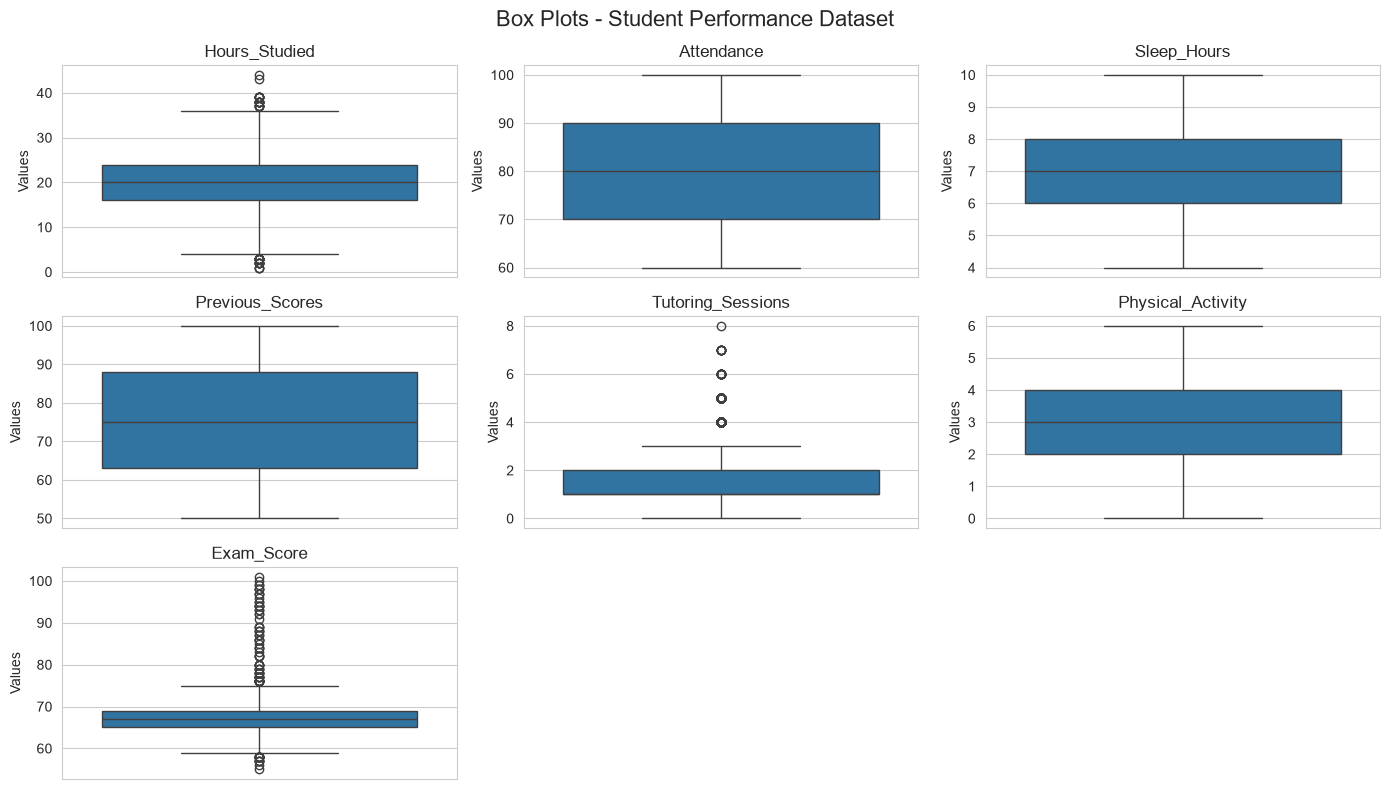

In [41]:

# ------------------------------------------
# Step 7: Box Plot
# ------------------------------------------

plt.figure(figsize=(14, 8))

for i, column in enumerate(features, 1):
    plt.subplot(3, 3, i)

    sns.boxplot(
        y=plot_df[column]
    )

    plt.title(column)
    plt.ylabel("Values")

plt.suptitle(
    "Box Plots - Student Performance Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()



In [42]:
# Step 8: Correlation Matrix

correlation_matrix = plot_df.corr()

print("\nCorrelation Matrix:")
print(correlation_matrix)


Correlation Matrix:
                   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  \
Hours_Studied           1.000000   -0.009908     0.010977         0.024846   
Attendance             -0.009908    1.000000    -0.015918        -0.020186   
Sleep_Hours             0.010977   -0.015918     1.000000        -0.021750   
Previous_Scores         0.024846   -0.020186    -0.021750         1.000000   
Tutoring_Sessions      -0.014282    0.014324    -0.012216        -0.013122   
Physical_Activity       0.004624   -0.022435    -0.000378        -0.011274   
Exam_Score              0.445455    0.581072    -0.017022         0.175079   

                   Tutoring_Sessions  Physical_Activity  Exam_Score  
Hours_Studied              -0.014282           0.004624    0.445455  
Attendance                  0.014324          -0.022435    0.581072  
Sleep_Hours                -0.012216          -0.000378   -0.017022  
Previous_Scores            -0.013122          -0.011274    0.175079  
Tuto

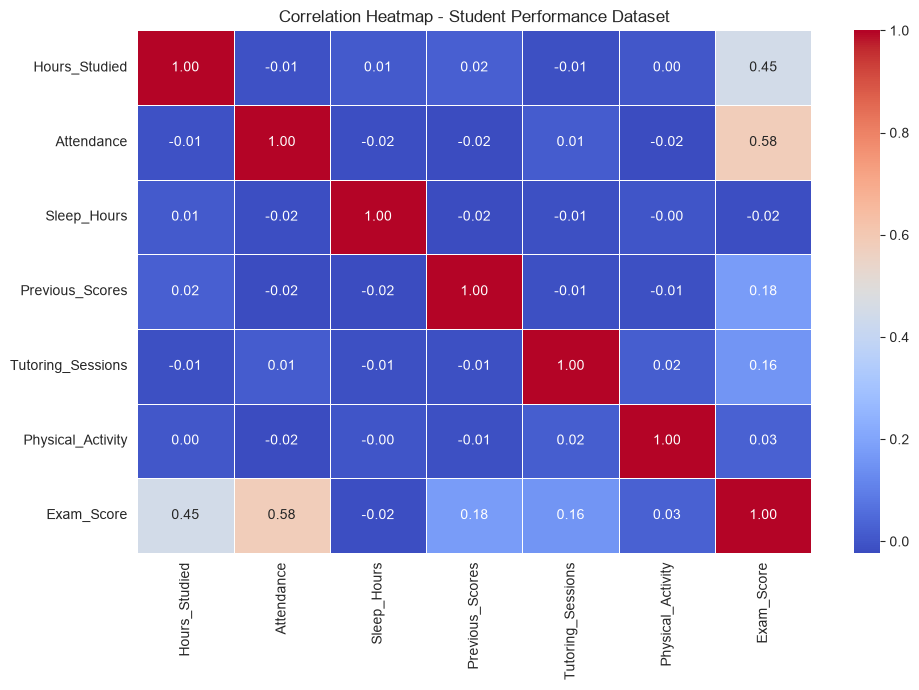

In [43]:

# ------------------------------------------
# Step 9: Correlation Heatmap
# ------------------------------------------

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title(
    "Correlation Heatmap - Student Performance Dataset"
)

plt.tight_layout()
plt.show()



In [44]:
# ------------------------------------------
# Step 10: Identify Strongest Correlations
# ------------------------------------------

corr_pairs = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
).stack()

print("\nStrongest Positive Correlation:")
print(corr_pairs.idxmax(), corr_pairs.max())

print("\nStrongest Negative Correlation:")
print(corr_pairs.idxmin(), corr_pairs.min())




Strongest Positive Correlation:
('Attendance', 'Exam_Score') 0.5810718633120632

Strongest Negative Correlation:
('Attendance', 'Physical_Activity') -0.02243470270349264


In [45]:
# ------------------------------------------
# Step 11: Identify Potential Outliers
# Using IQR Method
# ------------------------------------------

print("\nPotential Outliers in Each Feature:")

for column in features:

    Q1 = plot_df[column].quantile(0.25)
    Q3 = plot_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = plot_df[
        (plot_df[column] < lower_limit) |
        (plot_df[column] > upper_limit)
    ]

    print(column, ":", len(outliers))

print("\nAdvanced Visualization Completed Successfully!")



Potential Outliers in Each Feature:
Hours_Studied : 43
Attendance : 0
Sleep_Hours : 0
Previous_Scores : 0
Tutoring_Sessions : 430
Physical_Activity : 0
Exam_Score : 104

Advanced Visualization Completed Successfully!
